# Praktikum 1 : K-Means data kafe

In [1]:
# KMeans

# Persiapan data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('../../dataset_pbl/cafes.csv')

df.head()

,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,price_range,price_min,price_max,opening_hours,scraped_at,source_query
0,02069a80-3a5e-4a4a-8a48-39cf0b41b534,Warkop Djayantie,"Jl. Hasanudin, Samaan, Kec. Klojen, Kota Malan...",-7.970043,112.631764,4.7,167,Kedai Kopi,0813-3171-0980,instagram.com,Rp 1,1.0,1.0,Sabtu: 07.00–01.00; Minggu: 07.00–01.00; Senin...,2026-10-17T10:18:43.845715+00:00,NaN
1,05b8f28c-9c12-4abb-b317-5e3b26de0fd0,Pengyu Kopitiam,"Jl. Jenderal Basuki Rahmat No.6 C7, Kauman, Ke...",-7.979534,112.630695,4.5,1575,Kafe,NaN,instagram.com,Rp 25.000,25000.0,25000.0,Sabtu: 07.00–22.00; Minggu: 07.00–22.00; Senin...,2026-10-17T10:33:29.755703+00:00,NaN
2,060403fb-362b-4f51-8d3c-2c128ddd12c0,Daily Blend Coffee Malang,"Jl. Jakarta No.2, Penanggungan, Kec. Klojen, K...",-7.963036,112.625030,4.9,316,"Kedai Kopi, Santai, WFC, Kopi Enak, Estetik, O...",0858-9460-2611,NaN,Rp 25–50 rb,25000.0,50000.0,Senin: 07.00–23.30; Rabu: 07.00–23.30; Jumat: ...,2026-10-11T15:01:47.672667+00:00,NaN
3,075cb626-e6e0-4326-9b05-8b7bdbc1c77d,The Grove Cafe Malang,"Jl. Wilis No.23, Gading Kasri, Kec. Klojen, Ko...",-7.972555,112.618455,4.6,1772,"Kafe, Santai, Estetik, Keluarga, Pastry & Snac...",0888-8299-000,NaN,Rp 50–150 rb,50000.0,150000.0,Senin: 10.00–22.00; Rabu: 10.00–22.00; Jumat: ...,2026-10-11T14:06:15.915927+00:00,NaN
4,0a5edc1c-3fdf-494e-a3c9-5c321390322a,Khang Dimsum,"Jl. Sulfat No.54, Purwantoro, Kec. Blimbing, K...",-7.961104,112.651613,4.6,596,Restoran Dim Sum,0813-1888-8290,instagram.com,Rp 25.000,25000.0,25000.0,Sabtu: 12.00–21.00; Minggu: 12.00–21.00; Senin...,2026-10-17T10:48:05.712756+00:00,NaN


In [2]:
# Seleksi Fitur
X = df[['latitude', 'longitude', 'rating', 'review_count']]

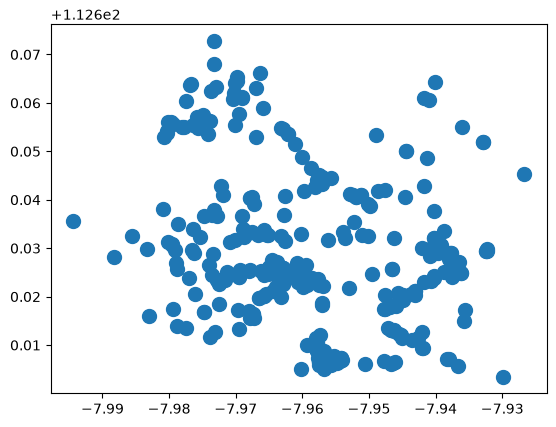

In [3]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

In [4]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)

from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

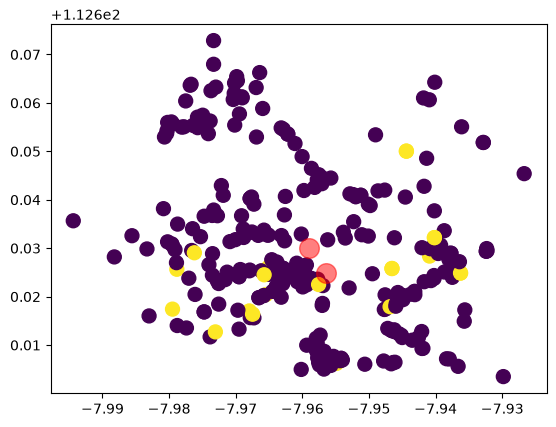

In [5]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

In [6]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 228402308.162062


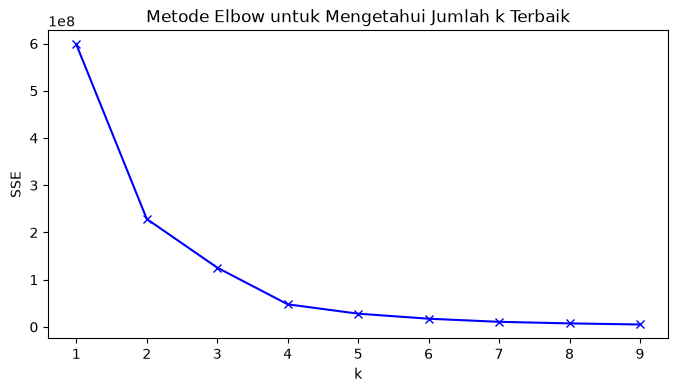

In [7]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)


# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [8]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=597998150.7659851
k=2; SSE=228485262.6566826
k=3; SSE=125468393.06003913
k=4; SSE=47818609.6642581
k=5; SSE=27998929.49940746
k=6; SSE=17372610.73782928
k=7; SSE=10766894.648376228
k=8; SSE=7446883.033165747
k=9; SSE=5102769.011058321
